---
title: "Summary of Chapter 3: Finite MDP"
author: "Fabian"
date: "2026-01-10"
categories: ["Reinforcement Learning"]
image: thumbnail.png
format:
  html:
    code-fold: false
    toc: true
jupyter: python3
draft: False
---

### **Summary of Chapter 3: Finite Markov Decision Processes**

This chapter formalizes the reinforcement learning problem using the framework of **Markov Decision Processes (MDPs)**.

**1. The Agent-Environment Interface**
The learner is the **agent**, and everything it interacts with is the **environment**. They interact at discrete time steps .

* **State ():** A representation of the environment at time .
* **Action ():** A decision made by the agent based on the state.
* **Reward ():** A numerical signal received after taking an action, defining the goal.



**2. Goals and Returns**
The agent's goal is to maximize the expected **return** (), which is the cumulative sum of rewards.

* **Discounting ():** To handle infinite horizons (continuing tasks), future rewards are discounted by a factor  (). A reward received  steps in the future is worth  times its immediate value.





**3. The Markov Property**
A state signal has the Markov property if it summarizes the past compactly; the future depends only on the current state and action, not on the history of events that led to it.

**4. Markov Decision Processes (MDPs)**
A finite MDP is defined by its state and action sets and the environment's dynamics, specifically the probability of transitioning to state  and receiving reward  given state  and action :


**5. Value Functions**
Value functions estimate "how good" it is to be in a given state (or take a given action).

* **State-Value Function ():** The expected return starting from state  and following policy .


* **Action-Value Function ():** The expected return starting from state , taking action , and *then* following policy .



**6. Bellman Equations**
These equations express the relationship between the value of a state and the values of its possible successor states. They are the cornerstone of calculating value functions.


**7. Optimal Value Functions**
Solving an RL task means finding a policy that achieves the most reward over the long run. The **optimal state-value function** () yields the maximum possible return for every state. It satisfies the **Bellman Optimality Equation**.

---

### **Python Implementation & Visualization**

The following code demonstrates the concepts of **MDPs**, **Returns**, and the **Bellman Equation** using the classic "GridWorld" example (Example 3.5/3.8 in the book ).

This code calculates the **State-Value Function** for a GridWorld where the agent tries to reach a goal state (A or B) to get a reward.



In [4]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- CONCEPT 1: The Environment (MDP) ---
class GridWorld:
    def __init__(self, size=5):
        self.size = size
        # A simple grid where moving off-grid returns you to the same cell with -1 reward
        self.actions = ['up', 'down', 'left', 'right']
        
        # Special states (Example 3.8 style)
        # Point A transitions to A_prime with +10 reward
        self.A_pos = (0, 1)
        self.A_prime = (4, 1)
        
        # Point B transitions to B_prime with +5 reward
        self.B_pos = (0, 3)
        self.B_prime = (2, 3)
        
        self.discount_gamma = 0.9

    def step(self, state, action):
        """
        Defines the p(s', r | s, a) dynamics of the MDP.
        Returns: (next_state, reward)
        """
        x, y = state
        
        # 1. Handle Special States (Teleporters)
        if state == self.A_pos:
            return self.A_prime, 10
        if state == self.B_pos:
            return self.B_prime, 5
        
        # 2. Handle Normal Moves
        if action == 'up':
            next_state = (max(x - 1, 0), y)
        elif action == 'down':
            next_state = (min(x + 1, self.size - 1), y)
        elif action == 'left':
            next_state = (x, max(y - 1, 0))
        elif action == 'right':
            next_state = (x, min(y + 1, self.size - 1))
            
        # 3. Handle Off-Grid Penalties
        # If the agent bumps into a wall (state doesn't change), reward is -1
        if next_state == state:
            return state, -1
        else:
            return next_state, 0


In [2]:
# --- CONCEPT 2: Policy & Value Function ---
def calculate_state_values(env, iterations=1000):
    """
    Iteratively solves the Bellman Expectation Equation:
    v(s) = sum( pi(a|s) * sum( p(s',r|s,a) * [r + gamma * v(s')] ) )
    
    For a uniform random policy, pi(a|s) = 0.25 for all actions.
    """
    # Initialize state-values to 0
    V = np.zeros((env.size, env.size))
    
    for i in range(iterations):
        new_V = np.zeros_like(V)
        for r in range(env.size):
            for c in range(env.size):
                state = (r, c)
                value_sum = 0
                
                # Bellman Equation Calculation
                for action in env.actions:
                    # In this deterministic environment, sum over s',r is just one term
                    next_state, reward = env.step(state, action)
                    nx, ny = next_state
                    
                    # Bellman update: r + gamma * V(s')
                    value_sum += 0.25 * (reward + env.discount_gamma * V[nx, ny])
                
                new_V[r, c] = value_sum
        
        # Check convergence (optional, for efficiency)
        if np.sum(np.abs(V - new_V)) < 1e-4:
            break
        V = new_V
        
    return V



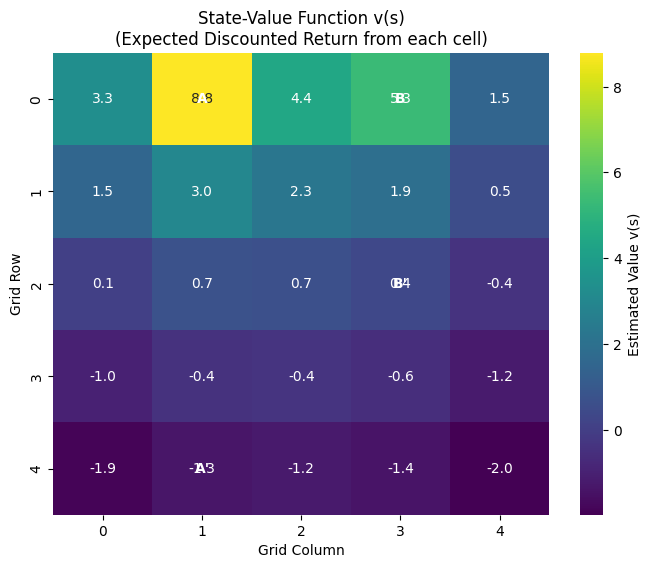

In [3]:
# --- VISUALIZATION ---
env = GridWorld()
final_values = calculate_state_values(env)

plt.figure(figsize=(8, 6))
sns.heatmap(final_values, annot=True, fmt=".1f", cmap="viridis", cbar_kws={'label': 'Estimated Value v(s)'})
plt.title("State-Value Function v(s)\n(Expected Discounted Return from each cell)")
plt.xlabel("Grid Column")
plt.ylabel("Grid Row")

# Annotate special states
plt.text(1.5, 0.5, 'A', color='white', ha='center', va='center', weight='bold')
plt.text(3.5, 0.5, 'B', color='white', ha='center', va='center', weight='bold')
plt.text(1.5, 4.5, "A'", color='white', ha='center', va='center', weight='bold')
plt.text(3.5, 2.5, "B'", color='white', ha='center', va='center', weight='bold')

plt.show()



### **Explanation of Visuals**

* **The Heatmap:** Represents . Lighter/brighter colors represent states with higher values.
* **State A (0, 1):** You will notice this cell has a high value. Even though moving *out* of A gives only , it transports you to , which might be in a safe area. The Bellman equation accounts for the immediate  *plus* the value of being in .
* 
**Edges:** Cells near the edges often have lower values (darker colors) because the "random policy" bumps into walls frequently, incurring a reward of .